# SAÉ S2.04 / R2.08 — Statistiques et méthode des k plus proches voisins
## Partie 2 : Qualité de l'air en Rhône-Alpes

- **Étudiant :** BARRY Mamadou Bailo
- **Groupe :** BUT Informatique S2
- **Date :** Juin 2026

## 1. Introduction

Dans cette SAÉ, on va étudier la qualité de l'air en région Auvergne-Rhône-Alpes avec le fichier de données `Indice_qualité_de_lair_-_ATMO.csv`.

Le but est de :
- Calculer les corrélations entre les concentrations des polluants.
- Faire un graphique en 2D pour montrer les données et faire une carte des prédictions.
- Coder l'algorithme des k plus proches voisins (k-NN) à la main pour deviner le code qualité (code_qual) sur un jeu de test.
- Comparer les prédictions chimiques avec des prédictions basées uniquement sur les coordonnées GPS (voisins géographiques).

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Chargement des données

On commence par charger le fichier avec pandas. On utilise le séparateur ; et l'encodage latin1 car il y a des accents dans les noms.

In [13]:
# Je charge les données
df = pd.read_csv("Indice_qualité_de_lair_-_ATMO.csv", sep=";", encoding="latin1")

# Je regarde les dimensions du tableau
print(df.shape)

# J'affiche les premières lignes pour vérifier que c'est bon
df.head()

(17995, 24)


,OBJECTID,date_ech,code_qual,lib_qual,coul_qual,date_dif,source,type_zone,code_zone,lib_zone,...,code_pm25,x_wgs84,y_wgs84,x_reg,y_reg,conc_no2,conc_so2,conc_o3,conc_pm10,conc_pm25
0,1,2022/02/06 00:00:00+00,2,Moyen,vert,2022/02/04 12:26:13+00,Atmo Auvergne-Rhône-Alpes,commune,42001,Aboën,...,1,4.131638,45.413611,788511.0,6479988.6,4.27,0.19,80.55,9.47,5.05
1,2,2022/02/05 00:00:00+00,2,Moyen,vert,2022/02/04 12:26:13+00,Atmo Auvergne-Rhône-Alpes,commune,42001,Aboën,...,1,4.131638,45.413611,788511.0,6479988.6,7.48,0.23,82.60,12.12,7.02
2,3,2022/02/04 00:00:00+00,2,Moyen,vert,2022/02/04 12:26:13+00,Atmo Auvergne-Rhône-Alpes,commune,42001,Aboën,...,1,4.131638,45.413611,788511.0,6479988.6,7.50,0.44,65.21,13.86,8.23
3,4,2022/02/03 00:00:00+00,2,Moyen,vert,2022/02/04 12:26:13+00,Atmo Auvergne-Rhône-Alpes,commune,42001,Aboën,...,1,4.131638,45.413611,788511.0,6479988.6,8.60,12.75,60.79,12.24,7.75
4,5,2022/02/06 00:00:00+00,2,Moyen,vert,2022/02/04 12:28:31+00,Atmo Auvergne-Rhône-Alpes,commune,74001,Abondance,...,1,6.722014,46.278888,986491.7,6582198.0,2.66,0.40,69.31,5.26,4.12


## 3. Préparation des données

On va garder seulement les colonnes actives (pour le k-NN) et les colonnes complémentaires. Ensuite on enlève les lignes vides.

In [14]:
# Les colonnes qu'on doit garder
colonnes_utiles = [
    'conc_no2', 'conc_so2', 'conc_o3', 'conc_pm10', 'conc_pm25',
    'code_qual', 'lib_zone', 'x_wgs84', 'y_wgs84'
]
df_prep = df[colonnes_utiles]

# Je nettoie les lignes vides
df_prep = df_prep.dropna()

# Je regarde la nouvelle taille
print(df_prep.shape)
df_prep.head()

(17964, 9)


,conc_no2,conc_so2,conc_o3,conc_pm10,conc_pm25,code_qual,lib_zone,x_wgs84,y_wgs84
0,4.27,0.19,80.55,9.47,5.05,2,Aboën,4.131638,45.413611
1,7.48,0.23,82.60,12.12,7.02,2,Aboën,4.131638,45.413611
2,7.50,0.44,65.21,13.86,8.23,2,Aboën,4.131638,45.413611
3,8.60,12.75,60.79,12.24,7.75,2,Aboën,4.131638,45.413611
4,2.66,0.40,69.31,5.26,4.12,2,Abondance,6.722014,46.278888


## 4. Étude des corrélations

On calcule la matrice de corrélation pour voir les relations entre les polluants.

In [15]:
actives = ['conc_no2', 'conc_so2', 'conc_o3', 'conc_pm10', 'conc_pm25']
df_prep[actives].corr()

,conc_no2,conc_so2,conc_o3,conc_pm10,conc_pm25
conc_no2,1.000000,0.293206,-0.458616,0.605556,0.601705
conc_so2,0.293206,1.000000,-0.263837,0.094101,0.178252
conc_o3,-0.458616,-0.263837,1.000000,-0.574058,-0.673499
conc_pm10,0.605556,0.094101,-0.574058,1.000000,0.916808
conc_pm25,0.601705,0.178252,-0.673499,0.916808,1.000000


### Justification des deux variables choisies :

On voit que `conc_o3` et `conc_no2` ont une corrélation assez faible (-0.458). Les autres comme pm10 et pm25 sont très corrélées entre elles (0.916) donc ça ne sert à rien de les prendre car elles donnent la même information.

On choisit donc de représenter la qualité de l'air en fonction de l'Ozone (`conc_o3`) et du Dioxyde d'azote (`conc_no2`) car ce sont les moins corrélées et elles apportent des informations différentes.

## 5. Nuage de points

On trace le nuage de points avec l'Ozone en abscisse et le NO2 en ordonnée. On utilise le code couleur demandé dans le sujet.

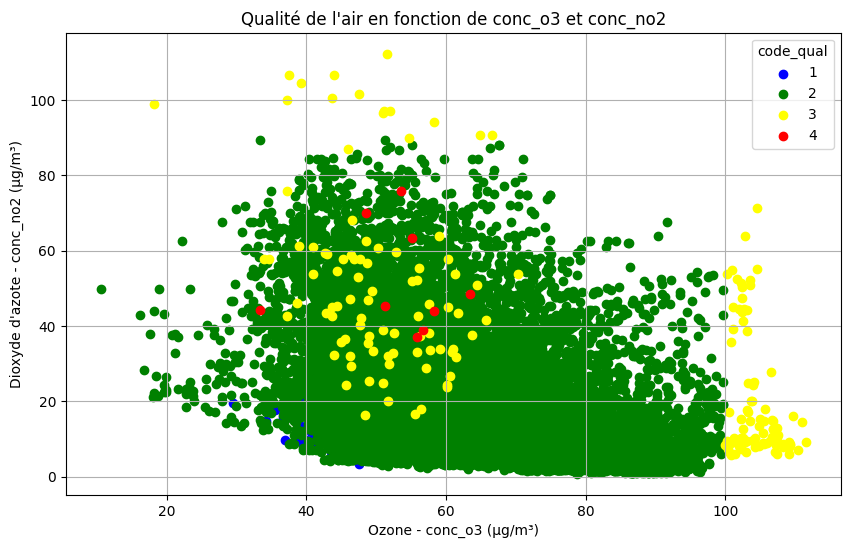

In [ ]:
# Liste des codes et des couleurs associées 
code_couleurs = [
    (1, 'blue'),
    (2, 'green'),
    (3, 'yellow'),
    (4, 'red'),
    (5, 'brown'),
    (6, 'darkviolet')
]

plt.figure(figsize=(10, 6))

# Je trace les points pour chaque qualité existante
for code, couleur in code_couleurs:
    masque = (df_prep['code_qual'] == code)
    if masque.sum() > 0:
        plt.scatter(
            df_prep.loc[masque, 'conc_o3'],
            df_prep.loc[masque, 'conc_no2'],
            color=couleur,
            label=code
        )

plt.title("Qualité de l'air en fonction de conc_o3 et conc_no2")
plt.xlabel("Ozone - conc_o3 (µg/m³)")
plt.ylabel("Dioxyde d'azote - conc_no2 (µg/m³)")
plt.legend(title="code_qual")
plt.grid(True)
plt.show()

## 6. Carte des prédictions k-NN

On crée une grille de 20x20. Pour chaque point (x, y) de la grille, on fait une prédiction k-NN (avec k=5) sur les 5 variables actives. Pour les 3 autres variables qu'on ne peut pas dessiner (SO2, PM10, PM25), on prend leur valeur moyenne dans le jeu de données.

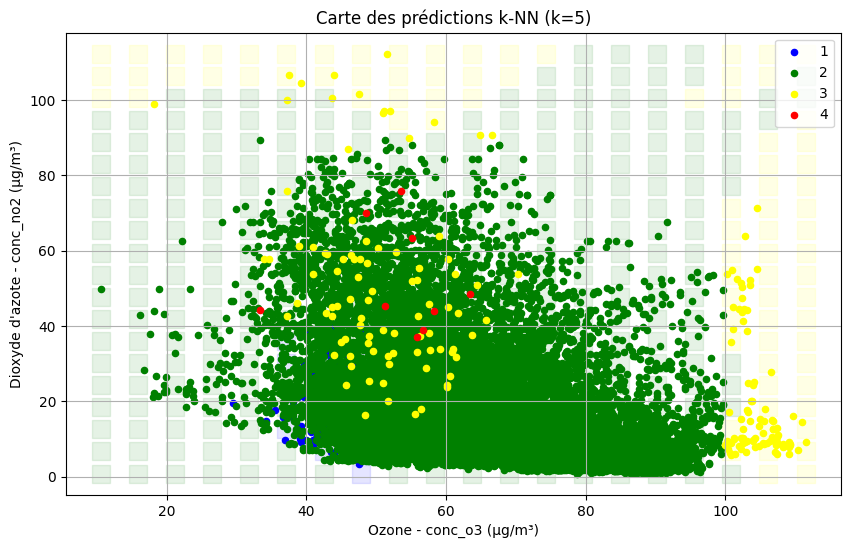

In [ ]:
# Moyennes pour le calcul en 5D
moy_so2 = df_prep['conc_so2'].mean()
moy_pm10 = df_prep['conc_pm10'].mean()
moy_pm25 = df_prep['conc_pm25'].mean()

# Limites de la grille
x_min, x_max = df_prep['conc_o3'].min(), df_prep['conc_o3'].max()
y_min, y_max = df_prep['conc_no2'].min(), df_prep['conc_no2'].max()

# Génération des points de la grille avec une boucle
n_grille = 20
axes_x = []
pas_x = (x_max - x_min) / (n_grille - 1)
for i in range(n_grille):
    axes_x.append(x_min + i * pas_x)

axes_y = []
pas_y = (y_max - y_min) / (n_grille - 1)
for i in range(n_grille):
    axes_y.append(y_min + i * pas_y)

grid_x_coords = []
grid_y_coords = []
grid_classes = []
k_voisins = 5

# je stocke les colonnes pour pas les relire à chaque fois
train_o3 = df_prep['conc_o3']
train_no2 = df_prep['conc_no2']
train_so2 = df_prep['conc_so2']
train_pm10 = df_prep['conc_pm10']
train_pm25 = df_prep['conc_pm25']

for x in axes_x:
    for y in axes_y:
        # Distance euclidienne 5D
        distances = (
            (train_o3 - x)**2 +
            (train_no2 - y)**2 +
            (train_so2 - moy_so2)**2 +
            (train_pm10 - moy_pm10)**2 +
            (train_pm25 - moy_pm25)**2
        )**0.5
        
        df_prep['tmp_dist'] = distances
        df_tri = df_prep.sort_values(by='tmp_dist')
        voisins = df_tri.head(k_voisins)
        
        # Vote majoritaire avec boucle 
        classes = voisins['code_qual']
        compteur = {}
        for c in classes:
            if c in compteur:
                compteur[c] += 1
            else:
                compteur[c] = 1
        classe_predite = -1
        max_votes = -1
        for c in compteur:
            if compteur[c] > max_votes:
                max_votes = compteur[c]
                classe_predite = c
        
        grid_x_coords.append(x)
        grid_y_coords.append(y)
        grid_classes.append(classe_predite)

# Je nettoie la colonne temporaire
df_prep = df_prep.drop(columns=['tmp_dist'])

plt.figure(figsize=(10, 6))

# Tracé des zones de décision de la grille
for code, couleur in code_couleurs:
    x_pts = [grid_x_coords[i] for i in range(len(grid_classes)) if grid_classes[i] == code]
    y_pts = [grid_y_coords[i] for i in range(len(grid_classes)) if grid_classes[i] == code]
    if len(x_pts) > 0:
        plt.scatter(x_pts, y_pts, color=couleur, alpha=0.1, marker='s', s=150)

# Superposition des vrais points
for code, couleur in code_couleurs:
    masque = (df_prep['code_qual'] == code)
    if masque.sum() > 0:
        plt.scatter(
            df_prep.loc[masque, 'conc_o3'],
            df_prep.loc[masque, 'conc_no2'],
            color=couleur,
            label=code,
            s=20
        )

plt.title("Carte des prédictions k-NN (k=5)")
plt.xlabel("Ozone - conc_o3 (µg/m³)")
plt.ylabel("Dioxyde d'azote - conc_no2 (µg/m³)")
plt.legend()
plt.grid(True)
plt.show()

## 7. Apprentissage supervisé

On va créer un jeu d'apprentissage et un jeu de test avec la méthode recommandée :
- Jeu d'apprentissage : première fois qu'on voit la commune (keep='first').
- Jeu de test : dernière fois qu'on voit la commune (keep='last').

In [18]:
# Séparation des données
df_app = df_prep.drop_duplicates(subset='lib_zone', keep='first').reset_index(drop=True)
df_test = df_prep.drop_duplicates(subset='lib_zone', keep='last').reset_index(drop=True)

print("taille apprentissage :", len(df_app))
print("taille test :", len(df_test))

taille apprentissage : 3913
taille test : 3913


## 8. Carte géographique du jeu de test

On trace les communes du jeu de test selon leurs coordonnées GPS et on dessine les contours des régions (Auvergne et Rhône-Alpes) avec les fichiers CSV.

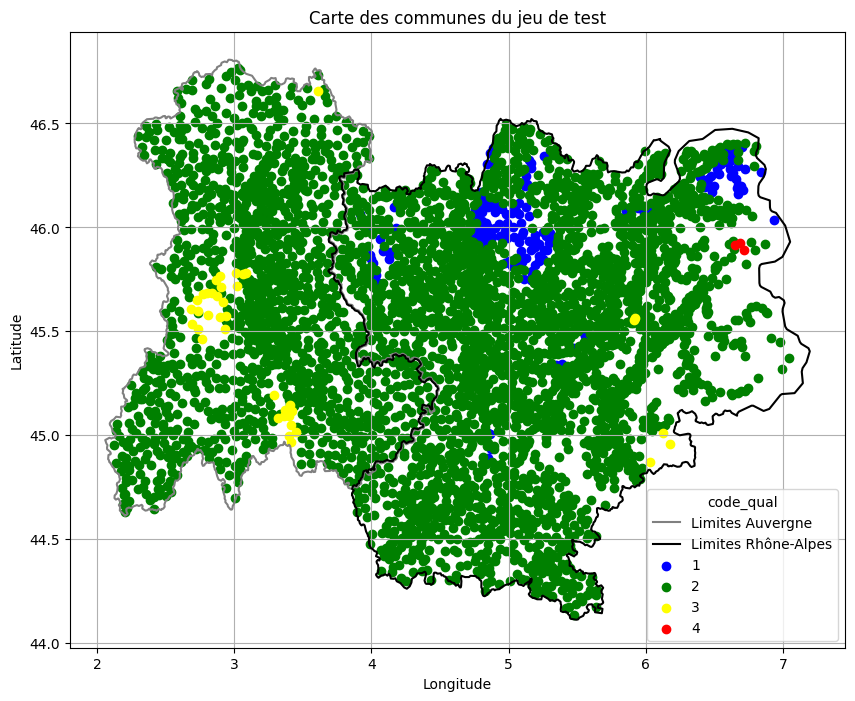

In [19]:
# Chargement des contours
cont_auvergne = pd.read_csv("auvergne.csv")
cont_rhone = pd.read_csv("rhone-alpes.csv")

plt.figure(figsize=(10, 8))

# Je trace les limites des régions
plt.plot(cont_auvergne['x'], cont_auvergne['y'], color='grey', label="Limites Auvergne")
plt.plot(cont_rhone['x'], cont_rhone['y'], color='black', label="Limites Rhône-Alpes")

# Je trace les communes de test
for code, couleur in code_couleurs:
    masque = (df_test['code_qual'] == code)
    if masque.sum() > 0:
        plt.scatter(
            df_test.loc[masque, 'x_wgs84'],
            df_test.loc[masque, 'y_wgs84'],
            color=couleur,
            label=code
        )

plt.title("Carte des communes du jeu de test")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="code_qual")
plt.grid(True)
plt.show()

## 9. Prédiction k-NN (sur toutes les variables actives)

On écrit la fonction de prédiction k-NN en 5D. Elle calcule les distances, trie, cherche les 5 voisins et effectue le vote.

In [20]:
# Fonction de prédiction pour les polluants chimiques
def predire_qualite_actives(point_test, base_apprentissage, k):
    no2, so2, o3, pm10, pm25 = point_test
    
    # Calcul des distances
    distances = (
        (base_apprentissage['conc_no2'] - no2)**2 +
        (base_apprentissage['conc_so2'] - so2)**2 +
        (base_apprentissage['conc_o3'] - o3)**2 +
        (base_apprentissage['conc_pm10'] - pm10)**2 +
        (base_apprentissage['conc_pm25'] - pm25)**2
    )**0.5
    
    # Ajout colonne temporaire et tri
    base_apprentissage['tmp_dist'] = distances
    base_triee = base_apprentissage.sort_values(by='tmp_dist')
    k_voisins = base_triee.head(k)
    
    # Vote manuel
    classes = k_voisins['code_qual']
    compteur = {}
    for c in classes:
        if c in compteur:
            compteur[c] += 1
        else:
            compteur[c] = 1
    prediction = -1
    max_votes = -1
    for c in compteur:
        if compteur[c] > max_votes:
            max_votes = compteur[c]
            prediction = c
    
    return prediction

# Boucle de prédiction
predictions_actives = []
k_knn = 5

for i in range(len(df_test)):
    pt = [
        df_test.loc[i, 'conc_no2'],
        df_test.loc[i, 'conc_so2'],
        df_test.loc[i, 'conc_o3'],
        df_test.loc[i, 'conc_pm10'],
        df_test.loc[i, 'conc_pm25']
    ]
    classe_estimee = predire_qualite_actives(pt, df_app, k_knn)
    predictions_actives.append(classe_estimee)

# Nettoyage
df_app = df_app.drop(columns=['tmp_dist'])
df_test['predict_actives'] = predictions_actives

# Calcul des bonnes prédictions et des erreurs
bonnes_predictions = len(df_test[df_test['code_qual'] == df_test['predict_actives']])
erreurs_predictions = len(df_test) - bonnes_predictions

print("Résultats pour k-NN chimique k = ")
print(k_knn)
print("- Bonnes prédictions : ", bonnes_predictions, "/ ", len(df_test))
print("- Erreurs de prédiction : ", erreurs_predictions)

Résultats pour k-NN chimique k = 
5
- Bonnes prédictions :  3727 /  3913
- Erreurs de prédiction :  186


## 10. Prédiction avec voisins géographiques

On fait la même chose mais en calculant la distance uniquement avec les coordonnées GPS x_wgs84 et y_wgs84.

In [21]:
# Fonction de prédiction géographique
def predire_qualite_geo(point_test_geo, base_apprentissage, k):
    x_gps, y_gps = point_test_geo
    
    # Distance 2D géographique
    distances = (
        (base_apprentissage['x_wgs84'] - x_gps)**2 +
        (base_apprentissage['y_wgs84'] - y_gps)**2
    )**0.5
    
    base_apprentissage['tmp_dist'] = distances
    base_triee = base_apprentissage.sort_values(by='tmp_dist')
    k_voisins = base_triee.head(k)
    
    # Vote manuel
    classes = k_voisins['code_qual']
    compteur = {}
    for c in classes:
        if c in compteur:
            compteur[c] += 1
        else:
            compteur[c] = 1
    prediction = -1
    max_votes = -1
    for c in compteur:
        if compteur[c] > max_votes:
            max_votes = compteur[c]
            prediction = c
    return prediction

# Boucle de prédiction géo
predictions_geo = []

for i in range(len(df_test)):
    pt_geo = [
        df_test.loc[i, 'x_wgs84'],
        df_test.loc[i, 'y_wgs84']
    ]
    classe_estimee_geo = predire_qualite_geo(pt_geo, df_app, k_knn)
    predictions_geo.append(classe_estimee_geo)

# Nettoyage
df_app = df_app.drop(columns=['tmp_dist'])
df_test['predict_geo'] = predictions_geo

# Calcul des erreurs
bonnes_predictions_geo = len(df_test[df_test['code_qual'] == df_test['predict_geo']])
erreurs_predictions_geo = len(df_test) - bonnes_predictions_geo

print("Résultats pour k-NN géographique k = ")
print(k_knn)
print("- Bonnes prédictions : ", bonnes_predictions_geo, "/ ", len(df_test))
print("- Erreurs de prédiction : ", erreurs_predictions_geo)

Résultats pour k-NN géographique k = 
5
- Bonnes prédictions :  3712 /  3913
- Erreurs de prédiction :  201


## 11. Conclusion

On a testé les deux prédictions avec k = 5 voisins :
- Les prédictions chimiques font 186 erreurs.
- Les prédictions géographiques (GPS) font 201 erreurs.

On voit que la méthode chimique fait moins d'erreurs que la méthode géographique. C'est donc plus précis et utile de prédire la qualité de l'air d'une ville en mesurant ses polluants chimiques plutôt qu'en prenant la moyenne de ses voisins géographiques.